## My first Python notebook

This notebook records the prompts, code, checks, and interpretations from Week 4.

In [1]:
print("Hello, digital history!")

Hello, digital history!


In [3]:
number_books = 500

In [4]:
print(number_books)

500


In [6]:
import pandas as pd

# Display settings so wide tables are easier to read
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.max_rows", 200)

# 1. LOAD THE FILE (read only; the file on disk is never modified)
# Only truly empty cells count as "missing". Texts like "NA" stay as written.
df = pd.read_csv("book-sample.csv", keep_default_na=False, na_values=[""])

# 2. SIZE OF THE TABLE
print("=" * 60)
print("2. SIZE OF THE TABLE")
print("=" * 60)
print(f"Number of rows (editions):  {df.shape[0]}")
print(f"Number of columns:          {df.shape[1]}")

# 3. FIRST FIVE ROWS
print("\n" + "=" * 60)
print("3. FIRST FIVE ROWS")
print("=" * 60)
display(df.head(5))

# 4. COLUMN NAMES AND DATA TYPES
print("\n" + "=" * 60)
print("4. COLUMN NAMES AND DATA TYPES")
print("(object = text; int64 = whole number; float64 = number with decimals)")
print("=" * 60)
for column_name, data_type in df.dtypes.items():
    print(f"{column_name:15s} -> {data_type}")

# 5. MISSING VALUES IN EVERY COLUMN
print("\n" + "=" * 60)
print("5. MISSING VALUES PER COLUMN")
print("=" * 60)
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent,
})
display(missing_table)

# 6. SUMMARY STATISTICS FOR year_numeric
print("\n" + "=" * 60)
print("6. SUMMARY OF year_numeric")
print("=" * 60)
# Work on a temporary copy of the column; df itself is not changed.
years = pd.to_numeric(df["year_numeric"], errors="coerce")
not_convertible = years.isna().sum() - df["year_numeric"].isna().sum()
print(f"Values used in the calculation:        {years.notna().sum()}")
print(f"Empty values ignored:                  {df['year_numeric'].isna().sum()}")
print(f"Non-numeric entries ignored:           {not_convertible}")
print(f"Minimum (earliest year):               {years.min()}")
print(f"Median (middle value):                 {years.median()}")
print(f"Mean (average):                        {years.mean():.1f}")
print(f"Maximum (latest year):                 {years.max()}")

# 7. COUNTS BY CATEGORY (missing values shown as "(missing)")
print("\n" + "=" * 60)
print("7. COUNTS BY CATEGORY")
print("=" * 60)
for column_name in ["decade", "country", "language", "format"]:
    counts = df[column_name].value_counts(dropna=False)
    if column_name == "decade":
        counts = counts.sort_index(na_position="last")  # chronological order
    table = pd.DataFrame({
        "count": counts,
        "percent": (counts / len(df) * 100).round(2),
    })
    table.index = table.index.fillna("(missing)")
    table.index.name = column_name
    print(f"\n--- Records by {column_name} ---")
    display(table)

# 8. IS edition_id UNIQUE?
print("\n" + "=" * 60)
print("8. IS edition_id UNIQUE?")
print("=" * 60)
n_missing_ids = df["edition_id"].isna().sum()
n_duplicated = df["edition_id"].duplicated(keep=False).sum()
print(f"All edition_id values unique? {df['edition_id'].is_unique}")
print(f"Missing edition_id values:    {n_missing_ids}")
print(f"Rows sharing an ID with another row: {n_duplicated}")
if n_duplicated > 0:
    print("\nRows with a repeated edition_id:")
    display(df[df["edition_id"].duplicated(keep=False)].sort_values("edition_id"))

2. SIZE OF THE TABLE
Number of rows (editions):  500
Number of columns:          11

3. FIRST FIVE ROWS


,edition_id,short_title,author,printer,place,year,language,format,country,year_numeric,decade
0,627908,Das Newe Testament,NaN,Kunigunde Hergot,Nürnberg,1535,German,8o,Holy Roman Empire,1535,1530s
1,698366,Trewung vom liebebande oder hertztrewen. Item:...,"Streuber, Peter",Zacharias Bärwald,Leipzig,1590,German,8o,Holy Roman Empire,1590,1590s
2,691468,Romischer Keyserlicher Majestat ordnung und Re...,NaN,Johann Schöffer,Mainz,1530,German,2o,Holy Roman Empire,1530,1530s
3,708446,Zwo predigten vom gantzen Christlichen wesen u...,"Spangenberg, Cyriacus",Samuel Emmel,Strasbourg,1564,German,8o,Holy Roman Empire,1564,1560s
4,640867,"Corpus juris civilis, institutiones dn. Joachi...",NaN,Nikolaus II Episcopius,Basel,1555,Latin,2o,Swiss Confederation,1555,1550s



4. COLUMN NAMES AND DATA TYPES
(object = text; int64 = whole number; float64 = number with decimals)
edition_id      -> int64
short_title     -> str
author          -> str
printer         -> str
place           -> str
year            -> str
language        -> str
format          -> str
country         -> str
year_numeric    -> int64
decade          -> str

5. MISSING VALUES PER COLUMN


,missing_count,missing_percent
edition_id,0,0.0
short_title,0,0.0
author,100,20.0
printer,0,0.0
place,0,0.0
year,0,0.0
language,14,2.8
format,19,3.8
country,0,0.0
year_numeric,0,0.0



6. SUMMARY OF year_numeric
Values used in the calculation:        500
Empty values ignored:                  0
Non-numeric entries ignored:           0
Minimum (earliest year):               1501
Median (middle value):                 1554.0
Mean (average):                        1553.5
Maximum (latest year):                 1600

7. COUNTS BY CATEGORY

--- Records by decade ---


,count,percent
decade,,
1500s,20,4.0
1510s,33,6.6
1520s,64,12.8
1530s,50,10.0
1540s,50,10.0
1550s,67,13.4
1560s,58,11.6
1570s,54,10.8
1580s,53,10.6


... (3 outputs left out)

,count,percent
language,,
Latin,200,40.0
German,168,33.6
Greek,31,6.2
French,21,4.2
(missing),14,2.8
Hebrew,14,2.8
Italian,13,2.6
English,10,2.0
Dutch,10,2.0



--- Records by format ---


,count,percent
format,,
8o,217,43.4
4o,180,36.0
2o,54,10.8
(missing),19,3.8
Broadsheet,11,2.2
16o,7,1.4
8o oblong,6,1.2
12o,4,0.8
4o oblong,2,0.4



8. IS edition_id UNIQUE?
All edition_id values unique? True
Missing edition_id values:    0
Rows sharing an ID with another row: 0


In [7]:
import re
import pandas as pd

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
INPUT_FILE = "historic_photographs_sample_dataset.csv"
OUTPUT_RECORDS = "photographs_for_rawgraphs.csv"
OUTPUT_COUNTS = "date_certainty_counts_for_rawgraphs.csv"

# A "four-digit year" = exactly four digits that are not part of a longer
# run of digits (so 18901 or 123456 will not produce a year).
YEAR_PATTERN = re.compile(r"(?<!\d)\d{4}(?!\d)")

# All possible labels, in the order of the precedence rules.
CERTAINTY_CATEGORIES = ["uncertain", "approximate", "supplied/inferred",
                        "range", "exact", "unparsed"]

# ---------------------------------------------------------------
# 1. LOAD THE FILE
# dtype=str keeps every cell exactly as written (no number conversion).
# keep_default_na=False stops texts such as "NA" or "None" from being
# silently turned into missing values. Empty cells become "".
# ---------------------------------------------------------------
df = pd.read_csv(INPUT_FILE, dtype=str, keep_default_na=False)

# ---------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ---------------------------------------------------------------
def find_years(date_text):
    """Return a list of all four-digit years found in the text, in order."""
    return YEAR_PATTERN.findall(date_text)

def classify_date(date_text):
    """Apply the precedence rules, from the first to the last."""
    cleaned = date_text.strip().lower()
    years = find_years(date_text)
    if "?" in date_text:
        return "uncertain"
    elif cleaned.startswith("c."):
        return "approximate"
    elif cleaned.startswith("["):
        return "supplied/inferred"
    elif len(years) >= 2:
        return "range"
    elif len(years) == 1:
        return "exact"
    else:
        return "unparsed"

# ---------------------------------------------------------------
# 3. CREATE THE OUTPUT TABLE (a copy; the raw columns stay untouched)
# ---------------------------------------------------------------
new_columns = ["year_start", "year_end", "date_certainty", "place_trimmed"]
assert not any(c in df.columns for c in new_columns), \
    "One of the new column names already exists in the input file."

out = df.copy()
years_found = df["date_raw"].map(find_years)   # one list of years per row

# Nullable integers (Int64): a row without a year stays empty instead of
# turning the whole column into decimals such as 1890.0
out["year_start"] = pd.Series(
    [int(y[0]) if len(y) >= 1 else None for y in years_found],
    index=out.index, dtype="Int64")

out["year_end"] = pd.Series(
    [int(y[1]) if len(y) >= 2 else (int(y[0]) if len(y) == 1 else None)
     for y in years_found],
    index=out.index, dtype="Int64")

out["date_certainty"] = df["date_raw"].map(classify_date)
out["place_trimmed"] = df["place_raw"].str.strip()

# ---------------------------------------------------------------
# 4. REPORT ON INPUT AND OUTPUT
# ---------------------------------------------------------------
print("=" * 60)
print("ROW COUNTS AND IDS")
print("=" * 60)
print(f"Input rows:                   {len(df)}")
print(f"Output rows:                  {len(out)}")
print(f"Unique record_id values:      {out['record_id'].nunique()}")

print("\n" + "=" * 60)
print("MISSING VALUES IN THE NEW COLUMNS")
print("(missing = truly empty value; empty text = a cell containing \"\")")
print("=" * 60)
text_columns = ["date_certainty", "place_trimmed"]
for col in new_columns:
    n_missing = int(out[col].isna().sum())
    n_empty_text = int((out[col] == "").sum()) if col in text_columns else 0
    print(f"{col:15s} missing: {n_missing:3d}   empty text: {n_empty_text:3d}")

print("\n" + "=" * 60)
print("DATE EXAMPLES (up to 2 rows per date_certainty category)")
print("=" * 60)
examples = out.groupby("date_certainty", sort=False).head(2)
if len(examples) < 10:   # make sure at least ten rows are shown
    extra = out.drop(examples.index).head(10 - len(examples))
    examples = pd.concat([examples, extra])
print(examples[["record_id", "date_raw", "year_start", "year_end",
                "date_certainty"]].to_string(index=False))

# ---------------------------------------------------------------
# 5. CHECKS (the code stops with an error message if one fails)
# ---------------------------------------------------------------
assert len(out) == 100, "The output does not have 100 rows."
assert out["record_id"].is_unique, "record_id is not unique."
assert all(c in out.columns for c in df.columns), "An original column is missing."
assert out[list(df.columns)].equals(df), "A raw value was changed."
assert set(out["date_certainty"]) <= set(CERTAINTY_CATEGORIES), \
    "Unexpected date_certainty label."
print("\nAll record-level checks passed.")

# ---------------------------------------------------------------
# 6. SAVE THE RECORD-LEVEL TABLE
# ---------------------------------------------------------------
out.to_csv(OUTPUT_RECORDS, index=False, encoding="utf-8")
print(f"Saved: {OUTPUT_RECORDS}")

# ---------------------------------------------------------------
# 7. AGGREGATED TABLE: one row per date_certainty category
# reindex() makes sure every category appears, even with a count of 0.
# ---------------------------------------------------------------
counts = (out["date_certainty"].value_counts()
          .reindex(CERTAINTY_CATEGORIES, fill_value=0)
          .rename_axis("date_certainty")
          .reset_index(name="record_count"))

print("\n" + "=" * 60)
print("RECORDS PER date_certainty CATEGORY")
print("=" * 60)
print(counts.to_string(index=False))

assert list(counts.columns) == ["date_certainty", "record_count"]
assert counts["date_certainty"].is_unique
assert counts["record_count"].sum() == 100, "record_count does not sum to 100."
print("\nAggregation check passed: record_count sums to 100.")

counts.to_csv(OUTPUT_COUNTS, index=False, encoding="utf-8")
print(f"Saved: {OUTPUT_COUNTS}")

ROW COUNTS AND IDS
Input rows:                   100
Output rows:                  100
Unique record_id values:      100

MISSING VALUES IN THE NEW COLUMNS
(missing = truly empty value; empty text = a cell containing "")
year_start      missing:   1   empty text:   0
year_end        missing:   1   empty text:   0
date_certainty  missing:   0   empty text:   0
place_trimmed   missing:   0   empty text:   0

DATE EXAMPLES (up to 2 rows per date_certainty category)
record_id    date_raw  year_start  year_end    date_certainty
  PHO-001   1930-1931        1930      1931             range
  PHO-002        1891        1891      1891             exact
  PHO-003       1896?        1896      1896         uncertain
  PHO-004   1892-1893        1892      1893             range
  PHO-005      [1924]        1924      1924 supplied/inferred
  PHO-006     c. 1935        1935      1935       approximate
  PHO-008 10 Feb 1933        1933      1933             exact
  PHO-011      [1935]        1935    

In [8]:
import re
import pandas as pd

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
INPUT_FILE = "historic_photographs_sample_dataset.csv"
OUTPUT_RECORDS = "photographs_for_rawgraphs.csv"
OUTPUT_COUNTS = "date_certainty_counts_for_rawgraphs.csv"

# A "four-digit year" = exactly four digits that are not part of a longer
# run of digits (so 18901 or 123456 will not produce a year).
YEAR_PATTERN = re.compile(r"(?<!\d)\d{4}(?!\d)")

# NEW: texts that mean "this record has no date".
# They are written WITHOUT dots, spaces, brackets or question marks,
# because the code removes those characters before comparing.
# "n.d.", "N. D.", "[n.d.]" and "nd" all become "nd".
# To catch more wordings, add them to this set (lowercase, no punctuation).
UNDATED_MARKERS = {"nd", "nodate", "undated", "unknown", "dateunknown",
                   "sd", "sinedato"}

# All possible labels, in the order of the precedence rules.
CERTAINTY_CATEGORIES = ["undated", "uncertain", "approximate",
                        "supplied/inferred", "range", "exact", "unparsed"]

# ---------------------------------------------------------------
# 1. LOAD THE FILE
# dtype=str keeps every cell exactly as written (no number conversion).
# keep_default_na=False stops texts such as "NA" or "None" from being
# silently turned into missing values. Empty cells become "".
# ---------------------------------------------------------------
df = pd.read_csv(INPUT_FILE, dtype=str, keep_default_na=False)

# ---------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ---------------------------------------------------------------
def find_years(date_text):
    """Return a list of all four-digit years found in the text, in order."""
    return YEAR_PATTERN.findall(date_text)

def is_undated_marker(date_text):
    """True if the WHOLE cell is only a 'no date' marker such as n.d."""
    squeezed = re.sub(r"[\s.\[\]()?,;:]", "", date_text.lower())
    return squeezed in UNDATED_MARKERS

def classify_date(date_text):
    """Apply the precedence rules, from the first to the last."""
    cleaned = date_text.strip().lower()
    years = find_years(date_text)
    if is_undated_marker(date_text):
        return "undated"
    elif "?" in date_text:
        return "uncertain"
    elif cleaned.startswith("c."):
        return "approximate"
    elif cleaned.startswith("["):
        return "supplied/inferred"
    elif len(years) >= 2:
        return "range"
    elif len(years) == 1:
        return "exact"
    else:
        return "unparsed"

# ---------------------------------------------------------------
# 3. CREATE THE OUTPUT TABLE (a copy; the raw columns stay untouched)
# ---------------------------------------------------------------
new_columns = ["year_start", "year_end", "date_certainty", "place_trimmed"]
assert not any(c in df.columns for c in new_columns), \
    "One of the new column names already exists in the input file."

out = df.copy()
years_found = df["date_raw"].map(find_years)   # one list of years per row

# Nullable integers (Int64): a row without a year stays empty instead of
# turning the whole column into decimals such as 1890.0
out["year_start"] = pd.Series(
    [int(y[0]) if len(y) >= 1 else None for y in years_found],
    index=out.index, dtype="Int64")

out["year_end"] = pd.Series(
    [int(y[1]) if len(y) >= 2 else (int(y[0]) if len(y) == 1 else None)
     for y in years_found],
    index=out.index, dtype="Int64")

out["date_certainty"] = df["date_raw"].map(classify_date)
out["place_trimmed"] = df["place_raw"].str.strip()

# ---------------------------------------------------------------
# 4. REPORT ON INPUT AND OUTPUT
# ---------------------------------------------------------------
print("=" * 60)
print("ROW COUNTS AND IDS")
print("=" * 60)
print(f"Input rows:                   {len(df)}")
print(f"Output rows:                  {len(out)}")
print(f"Unique record_id values:      {out['record_id'].nunique()}")

print("\n" + "=" * 60)
print("MISSING VALUES IN THE NEW COLUMNS")
print("(missing = truly empty value; empty text = a cell containing \"\")")
print("=" * 60)
text_columns = ["date_certainty", "place_trimmed"]
for col in new_columns:
    n_missing = int(out[col].isna().sum())
    n_empty_text = int((out[col] == "").sum()) if col in text_columns else 0
    print(f"{col:15s} missing: {n_missing:3d}   empty text: {n_empty_text:3d}")

print("\n" + "=" * 60)
print("DATE EXAMPLES (up to 2 rows per date_certainty category)")
print("=" * 60)
examples = out.groupby("date_certainty", sort=False).head(2)
if len(examples) < 10:   # make sure at least ten rows are shown
    extra = out.drop(examples.index).head(10 - len(examples))
    examples = pd.concat([examples, extra])
print(examples[["record_id", "date_raw", "year_start", "year_end",
                "date_certainty"]].to_string(index=False))

# ---------------------------------------------------------------
# 5. CHECKS (the code stops with an error message if one fails)
# ---------------------------------------------------------------
assert len(out) == 100, "The output does not have 100 rows."
assert out["record_id"].is_unique, "record_id is not unique."
assert all(c in out.columns for c in df.columns), "An original column is missing."
assert out[list(df.columns)].equals(df), "A raw value was changed."
assert set(out["date_certainty"]) <= set(CERTAINTY_CATEGORIES), \
    "Unexpected date_certainty label."
print("\nAll record-level checks passed.")

# ---------------------------------------------------------------
# 6. SAVE THE RECORD-LEVEL TABLE
# ---------------------------------------------------------------
out.to_csv(OUTPUT_RECORDS, index=False, encoding="utf-8")
print(f"Saved: {OUTPUT_RECORDS}")

# ---------------------------------------------------------------
# 7. AGGREGATED TABLE: one row per date_certainty category
# reindex() makes sure every category appears, even with a count of 0.
# ---------------------------------------------------------------
counts = (out["date_certainty"].value_counts()
          .reindex(CERTAINTY_CATEGORIES, fill_value=0)
          .rename_axis("date_certainty")
          .reset_index(name="record_count"))

print("\n" + "=" * 60)
print("RECORDS PER date_certainty CATEGORY")
print("=" * 60)
print(counts.to_string(index=False))

assert list(counts.columns) == ["date_certainty", "record_count"]
assert counts["date_certainty"].is_unique
assert counts["record_count"].sum() == 100, "record_count does not sum to 100."
print("\nAggregation check passed: record_count sums to 100.")

counts.to_csv(OUTPUT_COUNTS, index=False, encoding="utf-8")
print(f"Saved: {OUTPUT_COUNTS}")

ROW COUNTS AND IDS
Input rows:                   100
Output rows:                  100
Unique record_id values:      100

MISSING VALUES IN THE NEW COLUMNS
(missing = truly empty value; empty text = a cell containing "")
year_start      missing:   1   empty text:   0
year_end        missing:   1   empty text:   0
date_certainty  missing:   0   empty text:   0
place_trimmed   missing:   0   empty text:   0

DATE EXAMPLES (up to 2 rows per date_certainty category)
record_id    date_raw  year_start  year_end    date_certainty
  PHO-001   1930-1931        1930      1931             range
  PHO-002        1891        1891      1891             exact
  PHO-003       1896?        1896      1896         uncertain
  PHO-004   1892-1893        1892      1893             range
  PHO-005      [1924]        1924      1924 supplied/inferred
  PHO-006     c. 1935        1935      1935       approximate
  PHO-008 10 Feb 1933        1933      1933             exact
  PHO-011      [1935]        1935    

Rows in the input file: 500

RECORDED EDITIONS PER DECADE
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4

No missing values in the 'decade' column.

Check passed: bar counts add up to 500 rows.

Saved: book-records-by-decade.png


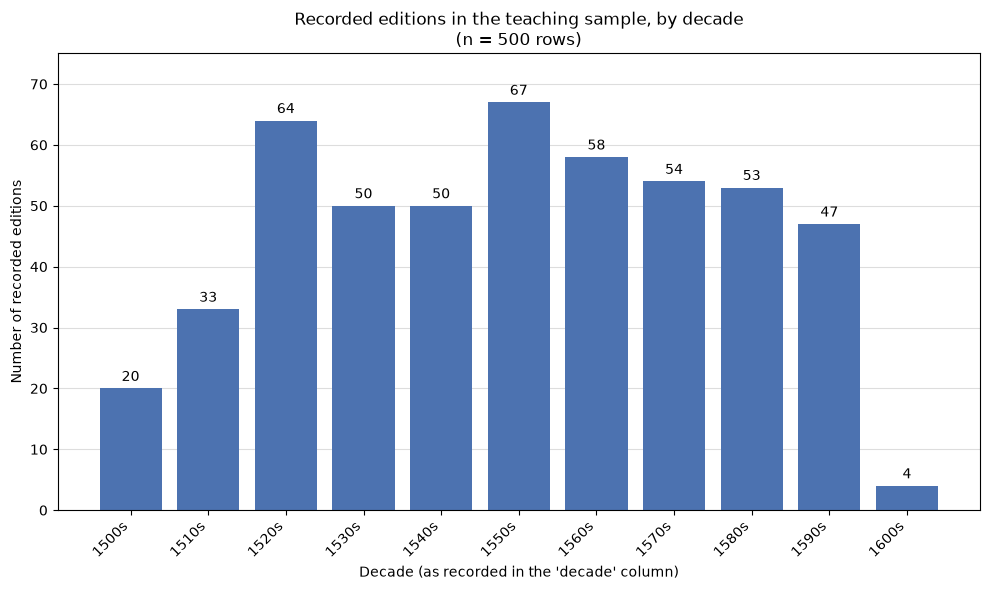

In [11]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
INPUT_FILE = "book-sample.csv"
OUTPUT_IMAGE = "book-records-by-decade.png"
MISSING_LABEL = "(missing)"

# ---------------------------------------------------------------
# 1. LOAD THE FILE (read only; the CSV on disk is never changed)
# Only truly empty cells count as missing; texts like "NA" stay as written.
# ---------------------------------------------------------------
df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])
n_rows = len(df)
assert "decade" in df.columns, "The file has no 'decade' column."
print(f"Rows in the input file: {n_rows}")

# ---------------------------------------------------------------
# 2. COUNT ROWS PER DECADE
# ---------------------------------------------------------------
n_missing = int(df["decade"].isna().sum())
present = df["decade"].value_counts()          # counts for non-empty labels
count_by_label = {str(label): int(n) for label, n in present.items()}
observed_labels = set(count_by_label)

# If every label looks like "1530s", add decades that have no records at
# all (count 0) between the earliest and latest decade. Otherwise a gap in
# the sample would look like two neighbouring decades on the chart.
labels = list(count_by_label)
if labels and all(re.fullmatch(r"\d{4}s", label) for label in labels):
    first = min(int(label[:4]) for label in labels)
    last = max(int(label[:4]) for label in labels)
    for year in range(first, last + 1, 10):
        count_by_label.setdefault(f"{year}s", 0)

# ---------------------------------------------------------------
# 3. SORT CHRONOLOGICALLY (by the four-digit start year, not alphabetically)
# Labels that do not start with four digits go after the dated ones.
# ---------------------------------------------------------------
def sort_key(label):
    match = re.match(r"\d{4}", label)
    if match:
        return (0, int(match.group()), "")
    return (1, 0, label)

ordered_labels = sorted(count_by_label, key=sort_key)
ordered_counts = [count_by_label[label] for label in ordered_labels]

# Keep missing values visible as their own bar (always last).
if n_missing > 0:
    ordered_labels.append(MISSING_LABEL)
    ordered_counts.append(n_missing)

table = pd.DataFrame({"decade": ordered_labels, "record_count": ordered_counts})

# ---------------------------------------------------------------
# 4. PRINT THE TABLE AND CHECK IT
# ---------------------------------------------------------------
print("\n" + "=" * 50)
print("RECORDED EDITIONS PER DECADE")
print("=" * 50)
print(table.to_string(index=False))

zero_filled = [label for label in ordered_labels
               if label not in observed_labels and label != MISSING_LABEL]
if zero_filled:
    print(f"\nDecades with no records (shown with a count of 0): {zero_filled}")
if n_missing == 0:
    print("\nNo missing values in the 'decade' column.")

assert table["record_count"].sum() == n_rows, \
    "The bar counts do not add up to the number of input rows."
print(f"\nCheck passed: bar counts add up to {n_rows} rows.")

# ---------------------------------------------------------------
# 5. DRAW THE BAR CHART
# ---------------------------------------------------------------
bar_colors = ["#999999" if label == MISSING_LABEL else "#4C72B0"
              for label in table["decade"]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(table["decade"], table["record_count"], color=bar_colors)
ax.bar_label(bars, padding=3)                    # print the count on each bar

ax.set_title(f"Recorded editions in the teaching sample, by decade\n(n = {n_rows} rows)")
ax.set_xlabel("Decade (as recorded in the 'decade' column)")
ax.set_ylabel("Number of recorded editions")
ax.set_ylim(0, max(table["record_count"]) * 1.12)   # numerical axis starts at zero
ax.set_axisbelow(True)
ax.yaxis.grid(True, color="#DDDDDD")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
fig.savefig(OUTPUT_IMAGE, dpi=300, bbox_inches="tight")
print(f"\nSaved: {OUTPUT_IMAGE}")
plt.show()

Rows in the input file: 500

RECORDED EDITIONS PER DECADE
decade  record_count
 1500s            20
 1510s            33
 1520s            64
 1530s            50
 1540s            50
 1550s            67
 1560s            58
 1570s            54
 1580s            53
 1590s            47
 1600s             4

No missing values in the 'decade' column.

Check passed: bar counts add up to 500 rows.

Saved: book-records-by-decade.png


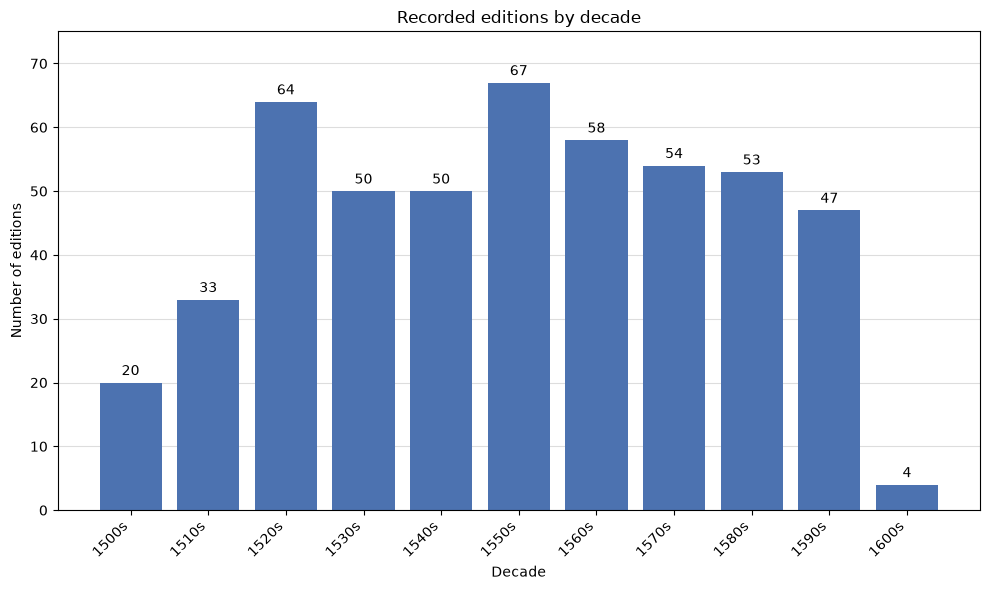

In [12]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
INPUT_FILE = "book-sample.csv"
OUTPUT_IMAGE = "book-records-by-decade.png"
MISSING_LABEL = "Missing"

# ---------------------------------------------------------------
# 1. LOAD THE FILE (read only; the CSV on disk is never changed)
# Only truly empty cells count as missing; texts like "NA" stay as written.
# ---------------------------------------------------------------
df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])
n_rows = len(df)
assert "decade" in df.columns, "The file has no 'decade' column."
print(f"Rows in the input file: {n_rows}")

# ---------------------------------------------------------------
# 2. COUNT ROWS PER DECADE
# ---------------------------------------------------------------
n_missing = int(df["decade"].isna().sum())
present = df["decade"].value_counts()          # counts for non-empty labels
count_by_label = {str(label): int(n) for label, n in present.items()}
observed_labels = set(count_by_label)

# If every label looks like "1530s", add decades that have no records at
# all (count 0) between the earliest and latest decade. Otherwise a gap in
# the sample would look like two neighbouring decades on the chart.
labels = list(count_by_label)
if labels and all(re.fullmatch(r"\d{4}s", label) for label in labels):
    first = min(int(label[:4]) for label in labels)
    last = max(int(label[:4]) for label in labels)
    for year in range(first, last + 1, 10):
        count_by_label.setdefault(f"{year}s", 0)

# ---------------------------------------------------------------
# 3. SORT CHRONOLOGICALLY (by the four-digit start year, not alphabetically)
# Labels that do not start with four digits go after the dated ones.
# ---------------------------------------------------------------
def sort_key(label):
    match = re.match(r"\d{4}", label)
    if match:
        return (0, int(match.group()), "")
    return (1, 0, label)

ordered_labels = sorted(count_by_label, key=sort_key)
ordered_counts = [count_by_label[label] for label in ordered_labels]

# Keep missing values visible as their own bar (always last).
if n_missing > 0:
    ordered_labels.append(MISSING_LABEL)
    ordered_counts.append(n_missing)

table = pd.DataFrame({"decade": ordered_labels, "record_count": ordered_counts})

# ---------------------------------------------------------------
# 4. PRINT THE TABLE AND CHECK IT
# ---------------------------------------------------------------
print("\n" + "=" * 50)
print("RECORDED EDITIONS PER DECADE")
print("=" * 50)
print(table.to_string(index=False))

zero_filled = [label for label in ordered_labels
               if label not in observed_labels and label != MISSING_LABEL]
if zero_filled:
    print(f"\nDecades with no records (shown with a count of 0): {zero_filled}")
if n_missing == 0:
    print("\nNo missing values in the 'decade' column.")

assert table["record_count"].sum() == n_rows, \
    "The bar counts do not add up to the number of input rows."
print(f"\nCheck passed: bar counts add up to {n_rows} rows.")

# ---------------------------------------------------------------
# 5. DRAW THE BAR CHART
# ---------------------------------------------------------------
bar_colors = ["#999999" if label == MISSING_LABEL else "#4C72B0"
              for label in table["decade"]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(table["decade"], table["record_count"], color=bar_colors)
ax.bar_label(bars, padding=3)                    # print the count on each bar

ax.set_title("Recorded editions by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Number of editions")
ax.set_ylim(0, max(table["record_count"]) * 1.12)   # numerical axis starts at zero
ax.set_axisbelow(True)
ax.yaxis.grid(True, color="#DDDDDD")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()
fig.savefig(OUTPUT_IMAGE, dpi=300, bbox_inches="tight")
print(f"\nSaved: {OUTPUT_IMAGE}")
plt.show()

In [14]:
import re
import pandas as pd

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
FILE = "StrVerz_Salzburg.csv"
COL_NAME = "Straßenname"
COL_SHORT = "Straßenname kurz"
# The PLZ column is spelled "Postleizahl" in your file; the code also accepts
# "Postleitzahl" (it looks for a column starting with "Postlei").

def heading(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

def share_table(label, counts):
    """Build a table with absolute counts, percentages and a total row."""
    total = sum(counts.values())
    table = pd.DataFrame({label: list(counts.keys()), "Count": list(counts.values())})
    table["Percent"] = (table["Count"] / total * 100).round(2)
    total_row = pd.DataFrame({label: ["Total"], "Count": [total], "Percent": [100.0]})
    return pd.concat([table, total_row], ignore_index=True)

def show(table):
    print(table.to_string(index=False, formatters={"Percent": "{:.2f} %".format}))

# ---------------------------------------------------------------
# 1. LOAD THE FILE (everything is read as text, so the leading zeros in
#    Straßenkennziffer and the PLZ stay exactly as written)
# Tries UTF-8 first, then Windows-1252; tab first, then ; and ,
# ---------------------------------------------------------------
df = None
for encoding in ("utf-8-sig", "cp1252"):
    for sep in ("\t", ";", ","):
        try:
            trial = pd.read_csv(FILE, sep=sep, dtype=str,
                                keep_default_na=False, encoding=encoding)
        except UnicodeDecodeError:
            break                      # wrong encoding: try the next one
        except pd.errors.ParserError:
            continue                   # wrong separator: try the next one
        if trial.shape[1] > 1:
            df, used_encoding, used_sep = trial, encoding, sep
            break
    if df is not None:
        break
if df is None:
    raise ValueError("The file could not be read as a table "
                     "(tried tab, semicolon and comma separators).")

df.columns = df.columns.str.strip()
plz_columns = [c for c in df.columns if c.lower().startswith("postlei")]
missing = [c for c in (COL_NAME, COL_SHORT) if c not in df.columns]
if missing or not plz_columns:
    raise KeyError(f"Expected columns not found: {missing or 'PLZ column'}. "
                   f"Columns in the file: {list(df.columns)}")
COL_PLZ = plz_columns[0]

heading("0. FILE CHECK")
print(f"Encoding / separator used:  {used_encoding} / {used_sep!r}")
print(f"Rows read (without header): {len(df)}   (expected 1111 = 1112 lines minus header)")
if len(df) != 1111:
    print("WARNING: the row count differs from the expected 1111.")
print(f"PLZ column used:            {COL_PLZ}")

# ---------------------------------------------------------------
# 2. UNIQUE STREET NAMES (used for every statistic EXCEPT the PLZ table)
# A name is identical to another if the text is exactly the same after
# removing spaces at the beginning and end. Upper/lower case counts as different.
# For repeated names, the FIRST row is kept.
# ---------------------------------------------------------------
named = pd.DataFrame({"name": df[COL_NAME].str.strip(),
                      "short": df[COL_SHORT].str.strip()})
n_blank_names = int((named["name"] == "").sum())
named = named[named["name"] != ""]
unique = named.drop_duplicates(subset="name", keep="first").copy()

name_counts = named["name"].value_counts()
n_repeated_names = int((name_counts > 1).sum())
n_inconsistent_short = int((named.groupby("name")["short"].nunique() > 1).sum())

heading("1. UNIQUE STREET NAMES")
print(f"Rows with a street name:                    {len(named)}")
print(f"Rows with an empty street name (ignored):   {n_blank_names}")
print(f"TOTAL UNIQUE STREET NAMES:                  {len(unique)}")
print(f"Names that appear in more than one row:     {n_repeated_names}")
print(f"  of these, names with different 'kurz' values: {n_inconsistent_short}")
if n_inconsistent_short:
    print("  (for those names, only the first row's 'kurz' value is used below)")

# ---------------------------------------------------------------
# 3. STREETS PER PLZ (uses ALL rows, so a street name in several rows
#    is counted once per row, i.e. once per PLZ entry)
# ---------------------------------------------------------------
plz_values = df[COL_PLZ].str.strip().replace("", "(missing)")
plz_counts = {plz: int(n) for plz, n in plz_values.value_counts().sort_index().items()}

heading("2. STREET ENTRIES PER PLZ (all rows, repeated names included)")
show(share_table("PLZ", plz_counts))

# ---------------------------------------------------------------
# 4. ABBREVIATED OR NOT? (unique names only)
# "Not abbreviated" = 'Straßenname kurz' is exactly the same as 'Straßenname'.
# ---------------------------------------------------------------
short_missing = unique["short"] == ""
not_abbreviated = (unique["short"] == unique["name"]) & ~short_missing
abbreviated = ~not_abbreviated & ~short_missing

heading("3. ABBREVIATION IN 'Straßenname kurz' (unique street names)")
abbr_counts = {
    "Not abbreviated (kurz = full name)": int(not_abbreviated.sum()),
    "Abbreviated (kurz differs)": int(abbreviated.sum()),
    "No 'kurz' value (empty)": int(short_missing.sum()),
}
show(share_table("Category", abbr_counts))

# ---------------------------------------------------------------
# 5. ENDINGS OF THE FULL STREET NAME (unique names only; upper/lower case ignored)
# In your excerpt the full name can itself be abbreviated
# ("Adam-Müller-Guttenbrunn-Str."), so a final "Str." is counted as -straße.
# If you do not want that, change the pattern to r"straße$".
# ---------------------------------------------------------------
ENDINGS = [
    ("-weg", re.compile(r"weg$", re.IGNORECASE)),
    ("-straße (incl. final 'Str.')", re.compile(r"(straße|str\.)$", re.IGNORECASE)),
    ("-gasse", re.compile(r"gasse$", re.IGNORECASE)),
    ("-platz", re.compile(r"platz$", re.IGNORECASE)),
    ("-kai", re.compile(r"kai$", re.IGNORECASE)),
]
NO_MATCH = "None of these endings"

def classify(name):
    for label, pattern in ENDINGS:
        if pattern.search(name):
            return label
    return NO_MATCH

categories


0. FILE CHECK
Encoding / separator used:  utf-8-sig / ','
Rows read (without header): 1111   (expected 1111 = 1112 lines minus header)
PLZ column used:            Postleizahl

1. UNIQUE STREET NAMES
Rows with a street name:                    1111
Rows with an empty street name (ignored):   0
TOTAL UNIQUE STREET NAMES:                  1088
Names that appear in more than one row:     22
  of these, names with different 'kurz' values: 0

2. STREET ENTRIES PER PLZ (all rows, repeated names included)
  PLZ  Count  Percent
 5020    933  83.98 %
 5023     81   7.29 %
 5026     79   7.11 %
 5061      7   0.63 %
 5071      5   0.45 %
 5081      2   0.18 %
 5082      4   0.36 %
Total   1111 100.00 %

3. ABBREVIATION IN 'Straßenname kurz' (unique street names)
                          Category  Count  Percent
Not abbreviated (kurz = full name)    233  21.42 %
        Abbreviated (kurz differs)    855  78.58 %
           No 'kurz' value (empty)      0   0.00 %
                             Tota

NameError: name 'categories' is not defined

In [17]:
import re
import pandas as pd

# ---------------------------------------------------------------
# SETTINGS
# ---------------------------------------------------------------
FILE = "StrVerz_Salzburg.csv"
COL_NAME = "Straßenname"
COL_SHORT = "Straßenname kurz"
# The PLZ column is spelled "Postleizahl" in your file; the code also accepts
# "Postleitzahl" (it looks for a column starting with "Postlei").

def heading(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

def share_table(label, counts):
    """Build a table with absolute counts, percentages and a total row."""
    total = sum(counts.values())
    table = pd.DataFrame({label: list(counts.keys()), "Count": list(counts.values())})
    table["Percent"] = (table["Count"] / total * 100).round(2)
    total_row = pd.DataFrame({label: ["Total"], "Count": [total], "Percent": [100.0]})
    return pd.concat([table, total_row], ignore_index=True)

def show(table):
    print(table.to_string(index=False, formatters={"Percent": "{:.2f} %".format}))

# ---------------------------------------------------------------
# 1. LOAD THE FILE (everything is read as text, so the leading zeros in
#    Straßenkennziffer and the PLZ stay exactly as written)
# Tries UTF-8 first, then Windows-1252; tab first, then ; and ,
# ---------------------------------------------------------------
df = None
for encoding in ("utf-8-sig", "cp1252"):
    for sep in ("\t", ";", ","):
        try:
            trial = pd.read_csv(FILE, sep=sep, dtype=str,
                                keep_default_na=False, encoding=encoding)
        except UnicodeDecodeError:
            break                      # wrong encoding: try the next one
        except pd.errors.ParserError:
            continue                   # wrong separator: try the next one
        if trial.shape[1] > 1:
            df, used_encoding, used_sep = trial, encoding, sep
            break
    if df is not None:
        break
if df is None:
    raise ValueError("The file could not be read as a table "
                     "(tried tab, semicolon and comma separators).")

df.columns = df.columns.str.strip()
plz_columns = [c for c in df.columns if c.lower().startswith("postlei")]
missing = [c for c in (COL_NAME, COL_SHORT) if c not in df.columns]
if missing or not plz_columns:
    raise KeyError(f"Expected columns not found: {missing or 'PLZ column'}. "
                   f"Columns in the file: {list(df.columns)}")
COL_PLZ = plz_columns[0]

heading("0. FILE CHECK")
print(f"Encoding / separator used:  {used_encoding} / {used_sep!r}")
print(f"Rows read (without header): {len(df)}   (expected 1111 = 1112 lines minus header)")
if len(df) != 1111:
    print("WARNING: the row count differs from the expected 1111.")
print(f"PLZ column used:            {COL_PLZ}")

# ---------------------------------------------------------------
# 2. UNIQUE STREET NAMES (used for every statistic EXCEPT the PLZ table)
# A name is identical to another if the text is exactly the same after
# removing spaces at the beginning and end. Upper/lower case counts as different.
# For repeated names, the FIRST row is kept.
# ---------------------------------------------------------------
named = pd.DataFrame({"name": df[COL_NAME].str.strip(),
                      "short": df[COL_SHORT].str.strip()})
n_blank_names = int((named["name"] == "").sum())
named = named[named["name"] != ""]
unique = named.drop_duplicates(subset="name", keep="first").copy()

name_counts = named["name"].value_counts()
n_repeated_names = int((name_counts > 1).sum())
n_inconsistent_short = int((named.groupby("name")["short"].nunique() > 1).sum())

heading("1. UNIQUE STREET NAMES")
print(f"Rows with a street name:                    {len(named)}")
print(f"Rows with an empty street name (ignored):   {n_blank_names}")
print(f"TOTAL UNIQUE STREET NAMES:                  {len(unique)}")
print(f"Names that appear in more than one row:     {n_repeated_names}")
print(f"  of these, names with different 'kurz' values: {n_inconsistent_short}")
if n_inconsistent_short:
    print("  (for those names, only the first row's 'kurz' value is used below)")

# ---------------------------------------------------------------
# 3. STREETS PER PLZ (uses ALL rows, so a street name in several rows
#    is counted once per row, i.e. once per PLZ entry)
# ---------------------------------------------------------------
plz_values = df[COL_PLZ].str.strip().replace("", "(missing)")
plz_counts = {plz: int(n) for plz, n in plz_values.value_counts().sort_index().items()}

heading("2. STREET ENTRIES PER PLZ (all rows, repeated names included)")
show(share_table("PLZ", plz_counts))

# ---------------------------------------------------------------
# 4. ABBREVIATED OR NOT? (unique names only)
# "Not abbreviated" = 'Straßenname kurz' is exactly the same as 'Straßenname'.
# ---------------------------------------------------------------
short_missing = unique["short"] == ""
not_abbreviated = (unique["short"] == unique["name"]) & ~short_missing
abbreviated = ~not_abbreviated & ~short_missing

heading("3. ABBREVIATION IN 'Straßenname kurz' (unique street names)")
abbr_counts = {
    "Not abbreviated (kurz = full name)": int(not_abbreviated.sum()),
    "Abbreviated (kurz differs)": int(abbreviated.sum()),
    "No 'kurz' value (empty)": int(short_missing.sum()),
}
show(share_table("Category", abbr_counts))

# ---------------------------------------------------------------
# 5. ENDINGS OF THE FULL STREET NAME (unique names only; upper/lower case ignored)
# In your excerpt the full name can itself be abbreviated
# ("Adam-Müller-Guttenbrunn-Str."), so a final "Str." is counted as -straße.
# If you do not want that, change the pattern to r"straße$".
# ---------------------------------------------------------------
ENDINGS = [
    ("-weg", re.compile(r"weg$", re.IGNORECASE)),
    ("-straße (incl. final 'Str.')", re.compile(r"(straße|str\.)$", re.IGNORECASE)),
    ("-gasse", re.compile(r"gasse$", re.IGNORECASE)),
    ("-platz", re.compile(r"platz$", re.IGNORECASE)),
    ("-kai", re.compile(r"kai$", re.IGNORECASE)),
]
NO_MATCH = "None of these endings"

def classify(name):
    for label, pattern in ENDINGS:
        if pattern.search(name):
            return label
    return NO_MATCH

categories = unique["name"].map(classify)
ending_counts = {label: int((categories == label).sum()) for label, _ in ENDINGS}
ending_counts[NO_MATCH] = int((categories == NO_MATCH).sum())
assert sum(ending_counts.values()) == len(unique), "Categories do not add up."

heading("4. ENDINGS OF STREET NAMES (unique street names)")
show(share_table("Ending", ending_counts))

n_str_dot = int(unique["name"].str.contains(r"str\.$", case=False, regex=True).sum())
print(f"\nOf the -straße names, {n_str_dot} are written with the abbreviation 'Str.' "
      f"in the Straßenname column.")
examples = unique.loc[categories == NO_MATCH, "name"].sort_values().head(100).tolist()
print("\nFirst 20 names that fall into 'None of these endings':")
print("; ".join(examples) if examples else "(none)")

# ---------------------------------------------------------------
# 6. TITLES IN STREET NAMES (unique names only, full-name column)
# The name is split into words at hyphens, spaces, slashes, commas and dots,
# so "Hofrat-Dr.-Karl-Müller-Weg" gives: Hofrat, Dr, Karl, Müller, Weg.
# A word counts as a title if it is in the list below (upper/lower case
# ignored, a final dot ignored). Only WHOLE words match, so "Hofratgasse"
# is not counted. To count more titles, add them to this list
# (lowercase, without dots): "Label shown": ["variant1", "variant2"].
# ---------------------------------------------------------------
TITLES = {
    "Academic": {
        "Dr./Doktor": ["dr", "doktor"], "DDr.": ["ddr"],
        "Prof./Professor": ["prof", "professor"], "Univ.": ["univ"],
        "Ing./Ingenieur": ["ing", "ingenieur"], "Dipl.": ["dipl"],
        "Mag./Magister": ["mag", "magister"],
    },
    "Noble": {
        "Graf/Gräfin": ["graf", "gräfin"], "Freiherr/Baron": ["freiherr", "baron"],
        "Fürst": ["fürst"], "Herzog/Herzogin": ["herzog", "herzogin"],
        "Erzherzog": ["erzherzog"], "Kaiser/Kaiserin": ["kaiser", "kaiserin"],
        "König/Königin": ["könig", "königin"], "Ritter": ["ritter"],
    },
    "Clerical": {
        "Papst": ["papst"], "Kardinal": ["kardinal"],
        "Erzbischof/Fürsterzbischof": ["erzbischof", "fürsterzbischof"],
        "Bischof": ["bischof"], "Abt": ["abt"], "Pater": ["pater"],
        "Pfarrer": ["pfarrer"], "Dechant": ["dechant"], "Prälat": ["prälat"],
        "Dompropst": ["dompropst"], "Domherr": ["domherr"],
        "Monsignore": ["monsignore"],
    },
    "Official / honorary": {
        "Hofrat": ["hofrat"], "Kommerzialrat": ["kommerzialrat"],
        "Regierungsrat": ["regierungsrat"], "Schulrat": ["schulrat"],
        "Baurat": ["baurat"], "Stadtrat": ["stadtrat"], "Landesrat": ["landesrat"],
        "Gemeinderat": ["gemeinderat"], "Bürgermeister": ["bürgermeister"],
        "Landeshauptmann": ["landeshauptmann"], "Bundespräsident": ["bundespräsident"],
        "Bundeskanzler": ["bundeskanzler"], "Präsident": ["präsident"],
        "Minister": ["minister"], "Konsul": ["konsul"], "Senator": ["senator"],
        "Direktor": ["direktor"],
    },
    "Military": {
        "General": ["general"], "Feldmarschall": ["feldmarschall"],
        "Oberst": ["oberst"], "Major": ["major"], "Hauptmann": ["hauptmann"],
        "Admiral": ["admiral"],
    },
}

# Look-up table: variant -> (group, label)
variant_lookup = {}
for group, titles in TITLES.items():
    for label, variants in titles.items():
        for variant in variants:
            variant_lookup[variant] = (group, label)

def find_titles(name):
    """Return the set of (group, label) pairs for every title word in a name."""
    found = set()
    for word in re.split(r"[-\s/,.]+", name):
        key = word.lower()
        if key in variant_lookup:
            found.add(variant_lookup[key])
    return found

unique["titles"] = unique["name"].map(find_titles)
n_unique = len(unique)
has_title = unique["titles"].map(len) > 0
n_with_title = int(has_title.sum())

heading("5. TITLES IN STREET NAMES (unique street names, full-name column)")
show(share_table("Contains a title?", {"At least one title": n_with_title,
                                       "No title": n_unique - n_with_title}))
print(f"\nNames containing more than one title (e.g. Hofrat + Dr.): "
      f"{int((unique['titles'].map(len) > 1).sum())}")

# Count per group and per title. A name can contain several titles, so the
# percentages below can add up to more than 100 %.
group_hits, title_hits = {}, {}
for found in unique["titles"]:
    for group in {g for g, _ in found}:
        group_hits[group] = group_hits.get(group, 0) + 1
    for pair in found:
        title_hits[pair] = title_hits.get(pair, 0) + 1

print("\n--- Names containing at least one title of each group ---")
group_table = pd.DataFrame({"Group": list(TITLES),
                            "Names": [group_hits.get(g, 0) for g in TITLES]})
group_table["Percent"] = (group_table["Names"] / n_unique * 100).round(2)
show(group_table)

print("\n--- Names containing each title (most frequent first) ---")
rows = sorted(title_hits.items(), key=lambda item: (-item[1], item[0][1]))
if rows:
    title_table = pd.DataFrame({"Title": [pair[1] for pair, n in rows],
                                "Group": [pair[0] for pair, n in rows],
                                "Names": [n for pair, n in rows]})
    title_table["Percent"] = (title_table["Names"] / n_unique * 100).round(2)
    show(title_table)
else:
    print("(no titles found)")

print("\nFirst 15 street names with a title (check these by eye):")
for _, row in unique[has_title].sort_values("name").head(15).iterrows():
    print(f"  {row['name']}   ->   {', '.join(sorted(label for _, label in row['titles']))}")
print("\nPercentages in section 5 are shares of all unique street names "
      f"({n_unique}).")


0. FILE CHECK
Encoding / separator used:  utf-8-sig / ','
Rows read (without header): 1111   (expected 1111 = 1112 lines minus header)
PLZ column used:            Postleizahl

1. UNIQUE STREET NAMES
Rows with a street name:                    1111
Rows with an empty street name (ignored):   0
TOTAL UNIQUE STREET NAMES:                  1088
Names that appear in more than one row:     22
  of these, names with different 'kurz' values: 0

2. STREET ENTRIES PER PLZ (all rows, repeated names included)
  PLZ  Count  Percent
 5020    933  83.98 %
 5023     81   7.29 %
 5026     79   7.11 %
 5061      7   0.63 %
 5071      5   0.45 %
 5081      2   0.18 %
 5082      4   0.36 %
Total   1111 100.00 %

3. ABBREVIATION IN 'Straßenname kurz' (unique street names)
                          Category  Count  Percent
Not abbreviated (kurz = full name)    233  21.42 %
        Abbreviated (kurz differs)    855  78.58 %
           No 'kurz' value (empty)      0   0.00 %
                             Tota